In [10]:
import numpy as np

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras import layers
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
#warnings.filterwarnings("ignore")
tf.random.set_seed(42)
np.random.seed(42)

dataset_dir = 'dataset/Plant_leaf_diseases_dataset_without_augmentation/Plant_leave_diseases_dataset_without_augmentation'
batch_size = 32
image_size = (256, 256)
image_shape = (256, 256, 3)
val_split = 0.2

# crop_disease_train_data = image_dataset_from_directory(
#                                 'dataset/Plant_leaf_diseases_dataset_without_augmentation\\Plant_leave_diseases_dataset_without_augmentation',
#                                 labels="inferred",
#                                 label_mode="categorical",
#                                 class_names=None,
#                                 color_mode="rgb",
#                                 batch_size=32,
#                                 image_size=image_size,
#                                 shuffle=True,
#                                 seed=123,
#                                 interpolation="bilinear",
#                                 verbose=True,
#                             )

train_data = image_dataset_from_directory(
    dataset_dir,
    validation_split=val_split,
    subset="training",
    seed=123,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True,
    label_mode="categorical"
)

# Validation dataset
val_data = image_dataset_from_directory(
    dataset_dir,
    validation_split=val_split,
    subset="validation",
    seed=123,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True,
    label_mode="categorical"
)

base_model = tf.keras.applications.EfficientNetB3(
    weights="imagenet",
    include_top=False,
    input_shape=image_shape
)
base_model.trainable = False

print(50*"-")
num_classes = len(train_data.class_names)
print(f"Num of classes: {num_classes}")

Found 55446 files belonging to 39 classes.
Using 44357 files for training.
Found 55446 files belonging to 39 classes.
Using 11089 files for validation.
--------------------------------------------------
Num of classes: 39


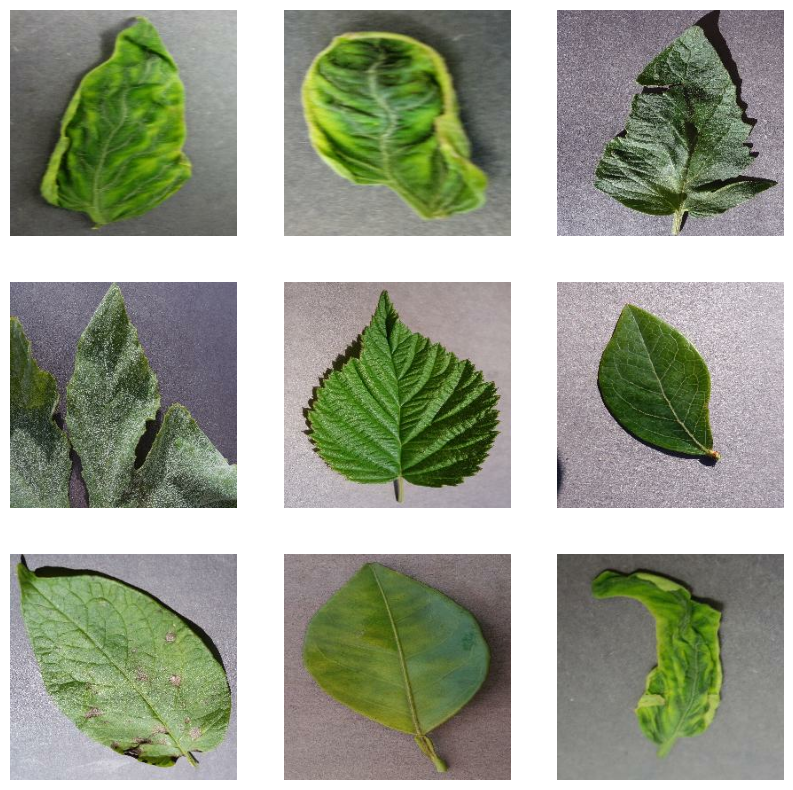

In [11]:
plt.figure(figsize=(10, 10))
for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")
plt.show()

In [12]:
# val_size = int(0.2 * len(crop_disease_train_data))
# val_data = crop_disease_train_data.take(val_size)
# train_data = crop_disease_train_data.skip(val_size)

AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(10000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)

data_augementation = Sequential([
    layers.Rescaling(1./255, input_shape=image_shape), 
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])



In [ ]:
model = Sequential([
    data_augementation, 
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(num_classes)
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 8, 8, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 39)             │        10,023 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,187,030 (42.68 MB)

 Trainable params: 403,495 (1.54 MB)

 Non-trainable params: 10,783,535 (41.14 MB)

: 

In [ ]:
model.compile(
    Adam(learning_rate=1e-4),
    loss=CategoricalCrossentropy(from_logits = True),
    metrics=["accuracy"]
    )

checkpoint = ModelCheckpoint(
    filepath="best_model.h5",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    callbacks=[checkpoint, early_stop],
)

Epoch 1/50


In [ ]:
model.save(image_dataset_from_directory.keras)

In [ ]:

# x = base_model.output
# x = tf.keras.layers.GlobalAveragePooling2D()(x)

# embedding_model = tf.keras.models.Model(inputs=base_model.input, outputs = x)

In [ ]:
# all_embeddings = []
# all_labels = []

# for images, labels in crop_disease_train_data:
#     batch_embeddings = embedding_model.predict(images)
#     all_embeddings.extend(batch_embeddings)
#     all_labels.extend(labels.numpy())

# embeddings = np.array(all_embeddings)
# labels = np.array(all_labels)

# print(f"Generated embeddings with shape: {embeddings.shape}")
# print(f"Corresponding labels with shape: {labels.shape}")

In [ ]:
import os
import glob

# Your base dataset directory
base_dir = 'dataset/Plant_leaf_diseases_dataset_without_augmentation\\Plant_leave_diseases_dataset_without_augmentation'

# Get a list of all class subdirectories
class_directories = [d for d in glob.glob(os.path.join(base_dir, '*')) if os.path.isdir(d)]
len(class_directories)


39

In [ ]:
# import numpy as np
# from sklearn.cluster import DBSCAN
# from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.vgg16 import preprocess_input

# for class_dir in class_directories[20:22]:
#     print(f"Processing directory: {class_dir}")
#     image_paths = glob.glob(os.path.join(class_dir, '*.jpg'))

#     if len(image_paths) < 2:
#         print(f"Skipping {class_dir}: Not enough images to perform clustering.")
#         continue

#     local_embeddings = []
#     for image_path in image_paths:
#         img = image.load_img(image_path, target_size=(224,224))
#         img_array = image.img_to_array(img)
#         img_array_expanded = np.expand_dims(img_array, axis=0)
#         img_preprocessed = preprocess_input(img_array_expanded)

#         embedding = embedding_model.predict(img_preprocessed, verbose = 0)[0]
#         local_embeddings.append(embedding)

#     local_embeddings = np.array(local_embeddings)
#     dbscan = DBSCAN(eps=0.3, min_samples=7,metric='cosine')
#     clusters = dbscan.fit_predict(local_embeddings)

#     anomaly_indices = np.where(clusters == -1)[0]

#     if len(anomaly_indices) > 0:
#         print(f"Found {len(anomaly_indices)} anomaly images in {class_dir}:")
#         for index in anomaly_indices:
#             anomaly_path = image_paths[index]
#             print(f"  Anomaly detected: {anomaly_path}") # D:\Developer\Python\AI\Projects\CropDisease\dataset\Plant_leaf_diseases_dataset_without_augmentation\Plant_leave_diseases_dataset_without_augmentation\Pepper,_bell___healthy
#     else:
#         print(f"No anomalies found in {class_dir}")


AttributeError: module 'keras._tf_keras.keras.layers' has no attribute 'RanomFlip'